In [ ]:
"""В данном модуле представлено сравнение точной и приближенной моделей
по методу Барттлета для оценки азимута прихода signalа
"""

%load_ext autoreload
%autoreload 2

import numpy as np
import time
from src.experiments import (stat_vs_params, calculate_mean, calculate_variance)
from src.functions import (calculate_bartlett_values, calculate_full_bartlett_values, get_sin_signal, get_impulse_signal, calculate_stiring_matrix, calculate_complex_stiring_matrix, calculate_full_bartlett_values,)
from src.configs.config import init_rng, restart_rng
import src.configs.config as cfg
import src.configs.comon as comon
from src.plotting import plot_variance_vs_param, plot_mean_vs_param
import os

origin_config = init_rng()
sin_signal = get_sin_signal
path = "attachment/images/report"
os.makedirs(path,exist_ok=True)

config_bartlett_aprox = dict(  # noqa: C408
                            energy_func=calculate_bartlett_values,
                            signal_func = sin_signal,
                            stiring_func = calculate_stiring_matrix,
                            is_CRN = False)
config_bartlett_exact  = dict(  # noqa: C408
                            energy_func = calculate_full_bartlett_values,
                            signal_func = sin_signal,
                            stiring_func = calculate_complex_stiring_matrix,
                            is_CRN = False)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [39]:
config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = config_parametrs1
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "target_phi",
    parametr_values = cfg.PHI_VALUES,
) 

var_bartlettt_vs_phis = stat_vs_params(config_params=config_parametrs1,
                                     stat_func = calculate_variance,
                                   **config_bartlett_aprox,
                                   **parametr_config)
var_bartlettt_vs_phis_complex = stat_vs_params(config_params = config_parametrs2,
                                             stat_func = calculate_variance,
                                             **config_bartlett_exact,
                                             **parametr_config)

config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = restart_rng(origin_config)
var_delta_abs = np.abs(np.array(var_bartlettt_vs_phis) - np.array(var_bartlettt_vs_phis_complex))
mean_bartlettt_vs_phis = stat_vs_params(config_params=config_parametrs1,
                                   stat_func = np.mean,
                                   **config_bartlett_aprox,
                                   **parametr_config
                                   )

mean_bartlettt_vs_phis_complex = stat_vs_params(config_params = config_parametrs2,
                                              stat_func = np.mean,
                                             **config_bartlett_exact,
                                             **parametr_config)
mean_delta_abs = np.abs(np.array(mean_bartlettt_vs_phis) - np.array(mean_bartlettt_vs_phis_complex))
end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='$\\varphi_0, град$', ylabel='$\\mathbb{E}[\\varepsilon]$, $град$'>)

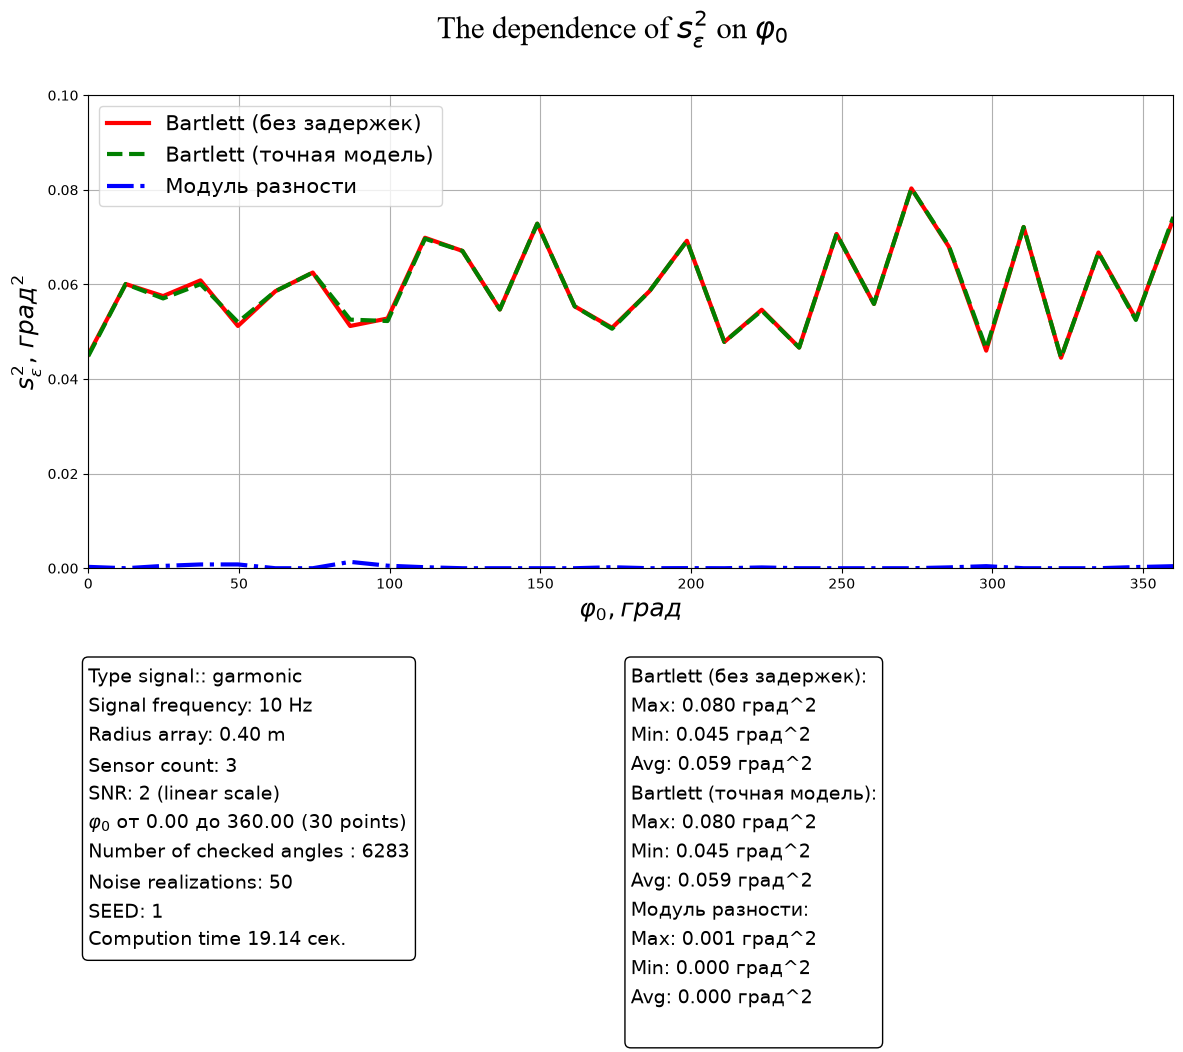

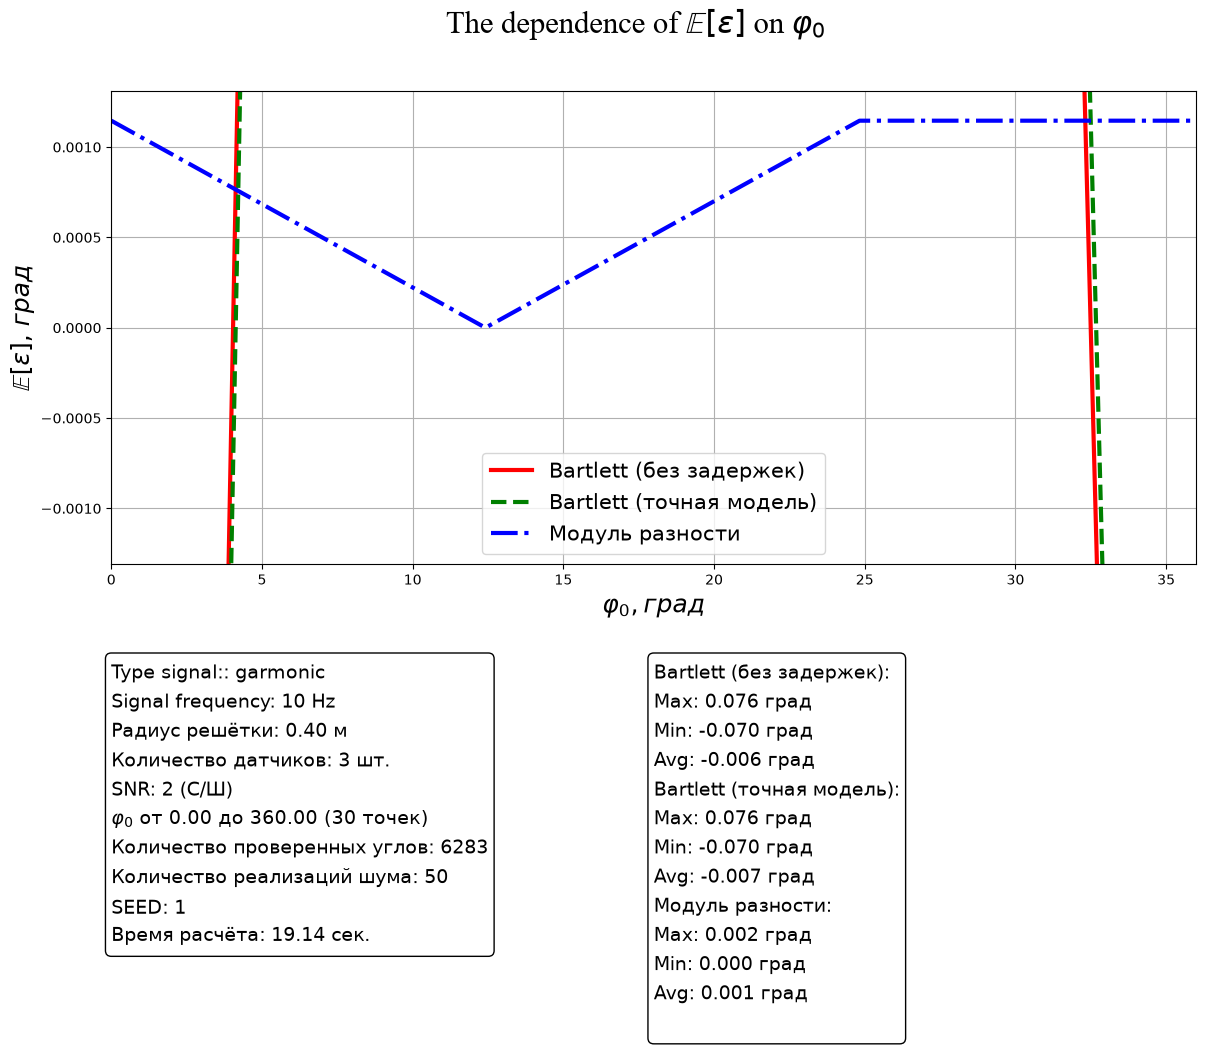

In [ ]:
plot_variance_vs_param(dict_values = {"Bartlett (без задержек)": var_bartlettt_vs_phis,
                                      "Bartlett (точная model)": var_bartlettt_vs_phis_complex,
                                      "Модуль разности": var_delta_abs},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (0.00*comon.CONST_RADIAN, 0.1*comon.CONST_RADIAN),
                       xlim = (0,360),
                       type_signal = "garmonic",
                       **parametr_config)
plot_mean_vs_param(dict_values = {"Bartlett (без задержек)": mean_bartlettt_vs_phis,
                                  "Bartlett (точная model)": mean_bartlettt_vs_phis_complex,
                                  "Модуль разности": mean_delta_abs},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (-0.075*comon.CONST_RADIAN, 0.075*comon.CONST_RADIAN),
                       xlim = (0,36),
                       type_signal = "garmonic",
                       **parametr_config)

In [41]:
config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = restart_rng(origin_config)
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "snr",
    parametr_values = cfg.SNR_VALUES,
) 
var_bartlettt_vs_snr = stat_vs_params(config_params=config_parametrs1,
                                    stat_func = calculate_variance,
                                    **config_bartlett_aprox,
                                    **parametr_config)
var_bartlettt_vs_snr_complex = stat_vs_params(config_params = config_parametrs2,
                                   stat_func = calculate_variance,
                                   **config_bartlett_exact,
                                   **parametr_config)
var_delta_abs = np.abs(np.array(var_bartlettt_vs_snr) - np.array(var_bartlettt_vs_snr_complex))
config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = restart_rng(origin_config)
mean_bartlettt_vs_snr = stat_vs_params(config_params=config_parametrs1,
                                    stat_func = np.mean,
                                    **config_bartlett_aprox,
                                    **parametr_config)
mean_bartlettt_vs_snr_complex = stat_vs_params(config_params=config_parametrs1,
                                    stat_func = np.mean,
                                    **config_bartlett_exact,
                                    **parametr_config)
mean_delta_abs = np.abs(np.array(mean_bartlettt_vs_snr) - np.array(mean_bartlettt_vs_snr_complex))
end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='SNR (c/ш)', ylabel='$\\mathbb{E}[\\varepsilon]$, $град$'>)

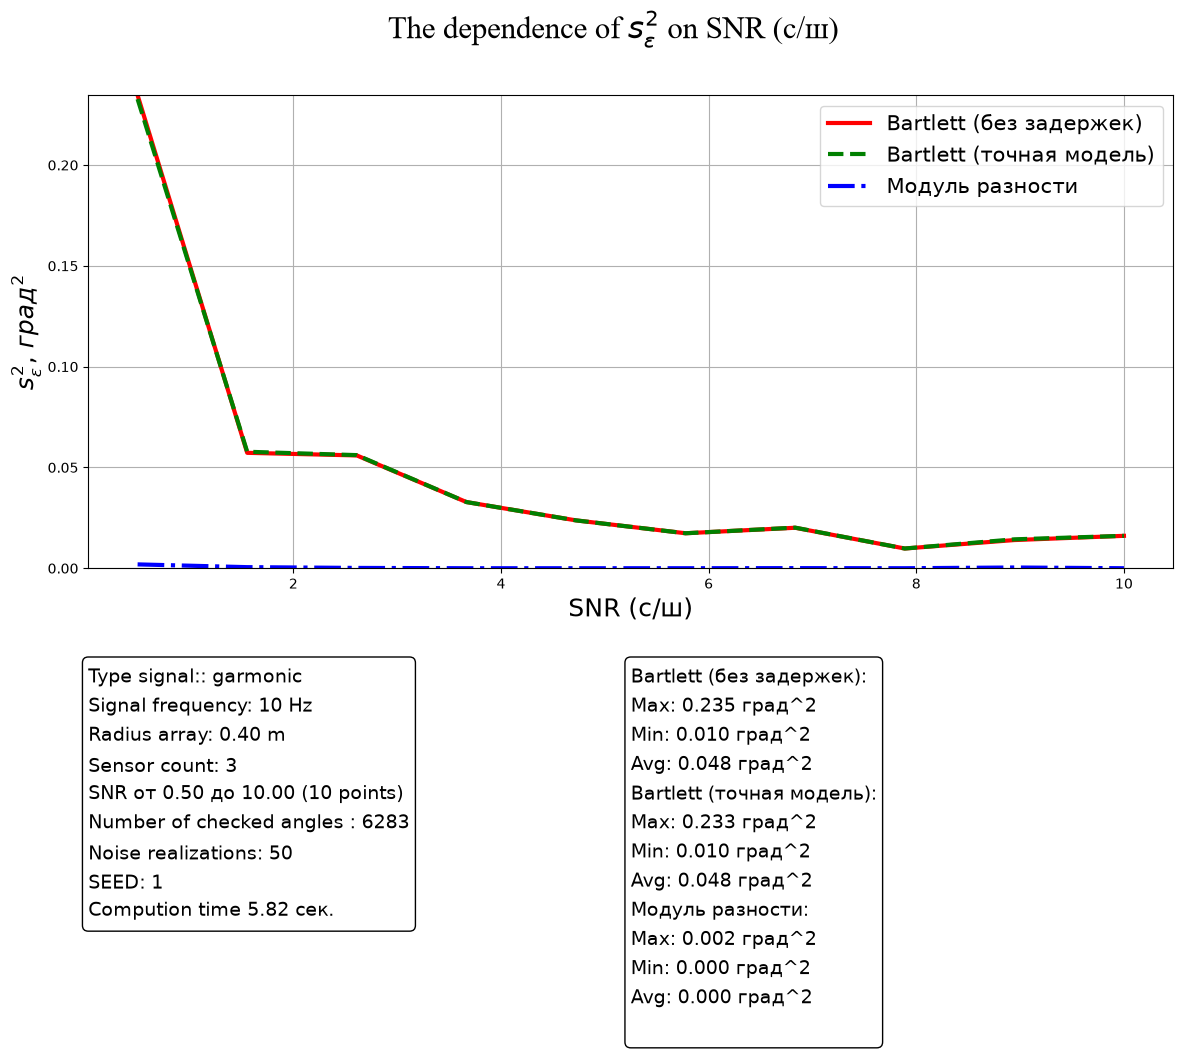

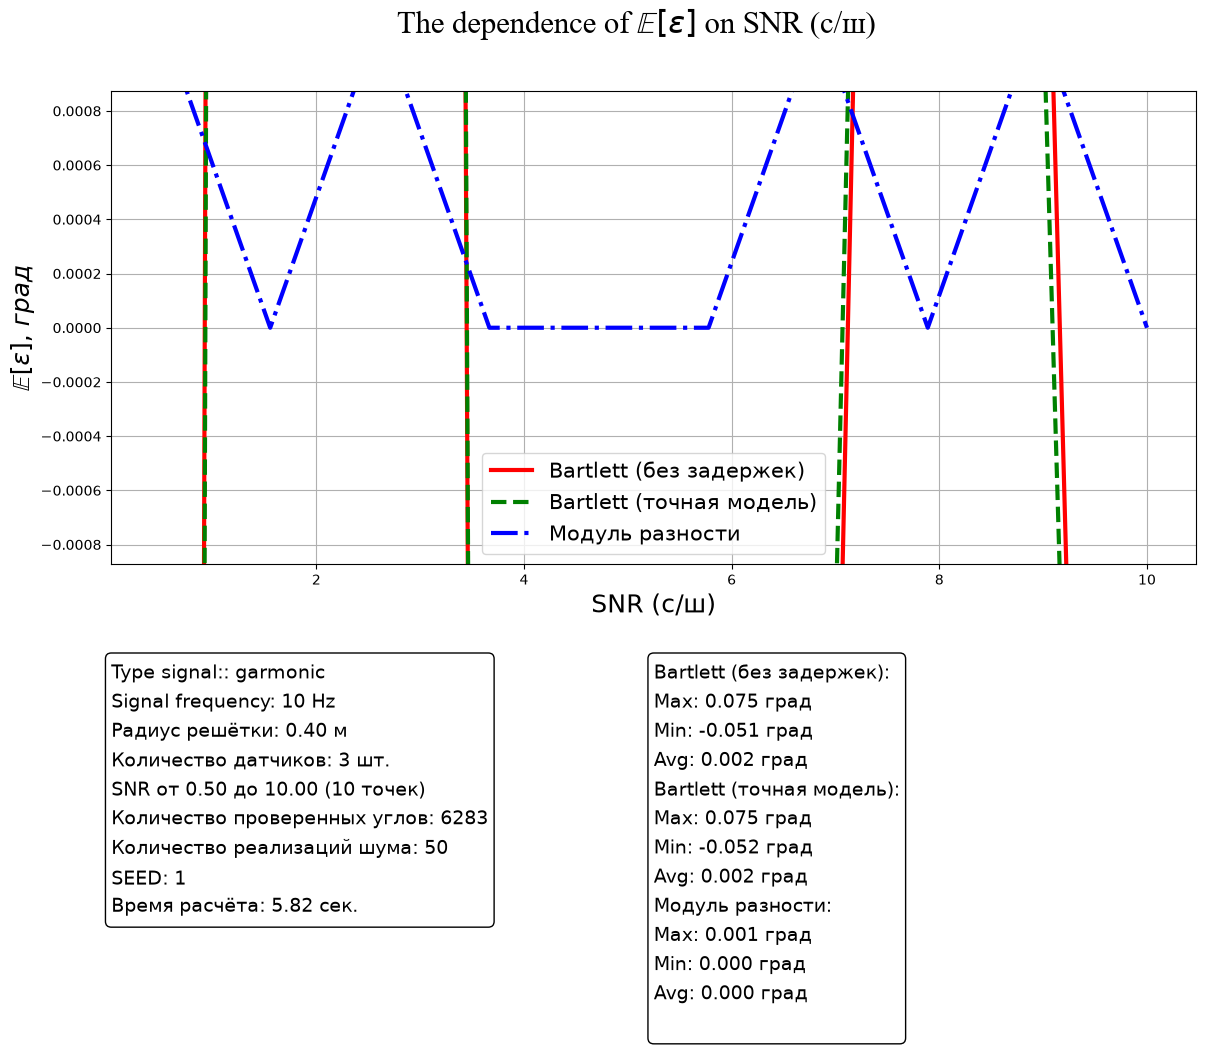

In [ ]:
plot_variance_vs_param(dict_values = {"Bartlett (без задержек)": var_bartlettt_vs_snr,
                                      "Bartlett (точная model)": var_bartlettt_vs_snr_complex,
                                      "Модуль разности": var_delta_abs},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (0, max(max(var_bartlettt_vs_snr),max(var_bartlettt_vs_snr_complex))),
                       type_signal = "garmonic",
                       **parametr_config)

plot_mean_vs_param(dict_values = {"Bartlett (без задержек)": mean_bartlettt_vs_snr,
                                 "Bartlett (точная model)": mean_bartlettt_vs_snr_complex,
                                 "Модуль разности": mean_delta_abs},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (-0.05*comon.CONST_RADIAN, 0.05*comon.CONST_RADIAN),
                       type_signal = "garmonic",
                       **parametr_config)

In [43]:
config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = restart_rng(origin_config)
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "R",
    parametr_values = cfg.RADIUS_VALUES,
) 
var_bartlettt_vs_r = stat_vs_params(config_params=config_parametrs1,
                                    stat_func = calculate_variance,
                                    **config_bartlett_aprox,
                                    **parametr_config)
var_bartlettt_vs_r_complex = stat_vs_params(config_params = config_parametrs2,
                                   stat_func = calculate_variance,
                                   **config_bartlett_exact,
                                   **parametr_config)
var_delta_abs = np.abs(np.array(var_bartlettt_vs_r) - np.array(var_bartlettt_vs_r_complex))
config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = restart_rng(origin_config)
mean_bartlettt_vs_r = stat_vs_params(config_params=config_parametrs1,
                                    stat_func = np.mean,
                                    **config_bartlett_aprox,
                                    **parametr_config)
mean_bartlettt_vs_r_complex = stat_vs_params(config_params=config_parametrs1,
                                    stat_func = np.mean,
                                    **config_bartlett_exact,
                                    **parametr_config)
mean_delta_abs = np.abs(np.array(mean_bartlettt_vs_r) - np.array(mean_bartlettt_vs_r_complex))
end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='R (радиус решётки АВП), м', ylabel='$\\mathbb{E}[\\varepsilon]$, $град$'>)

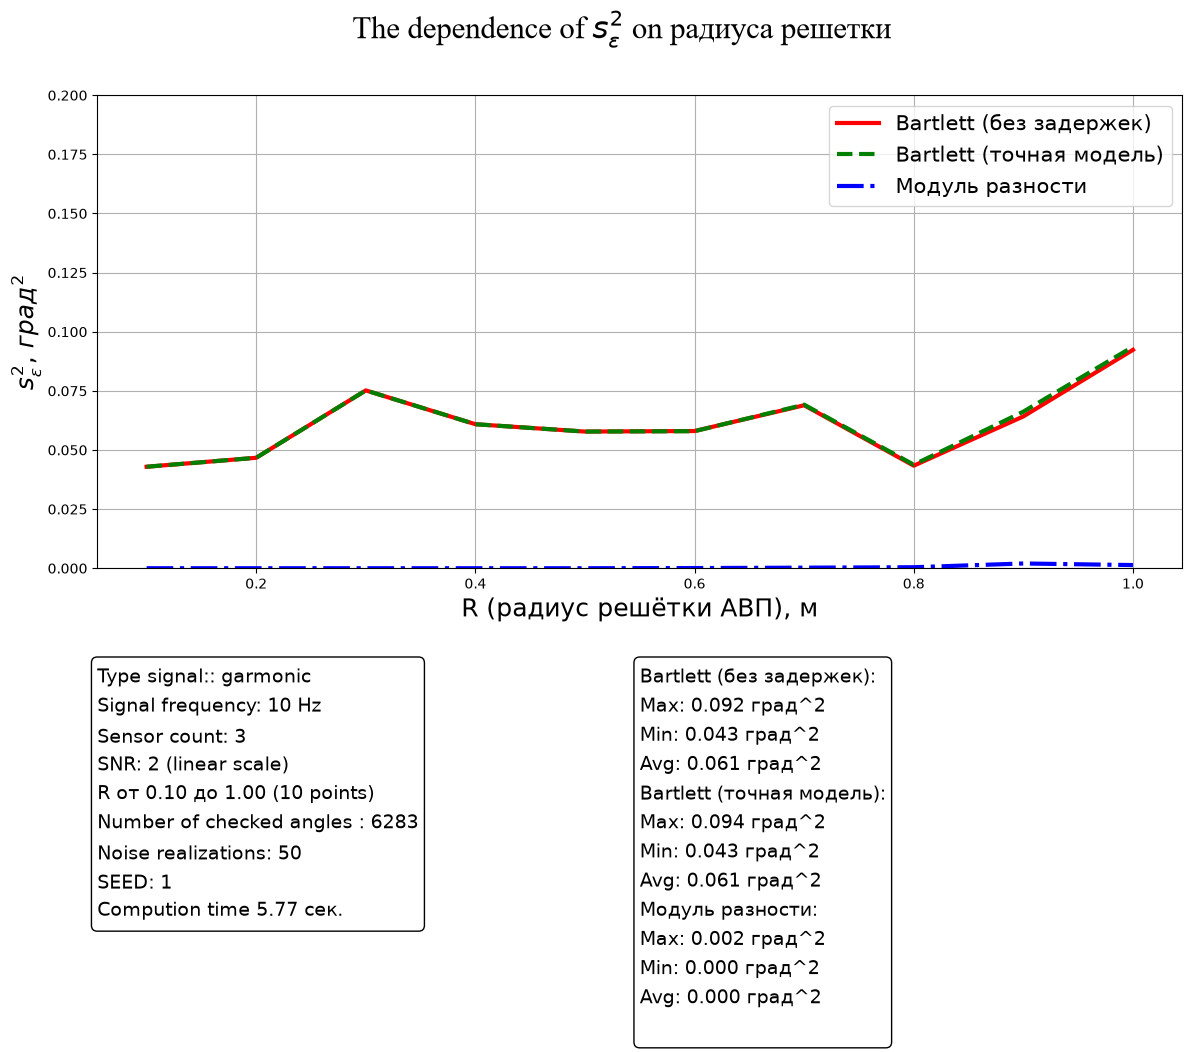

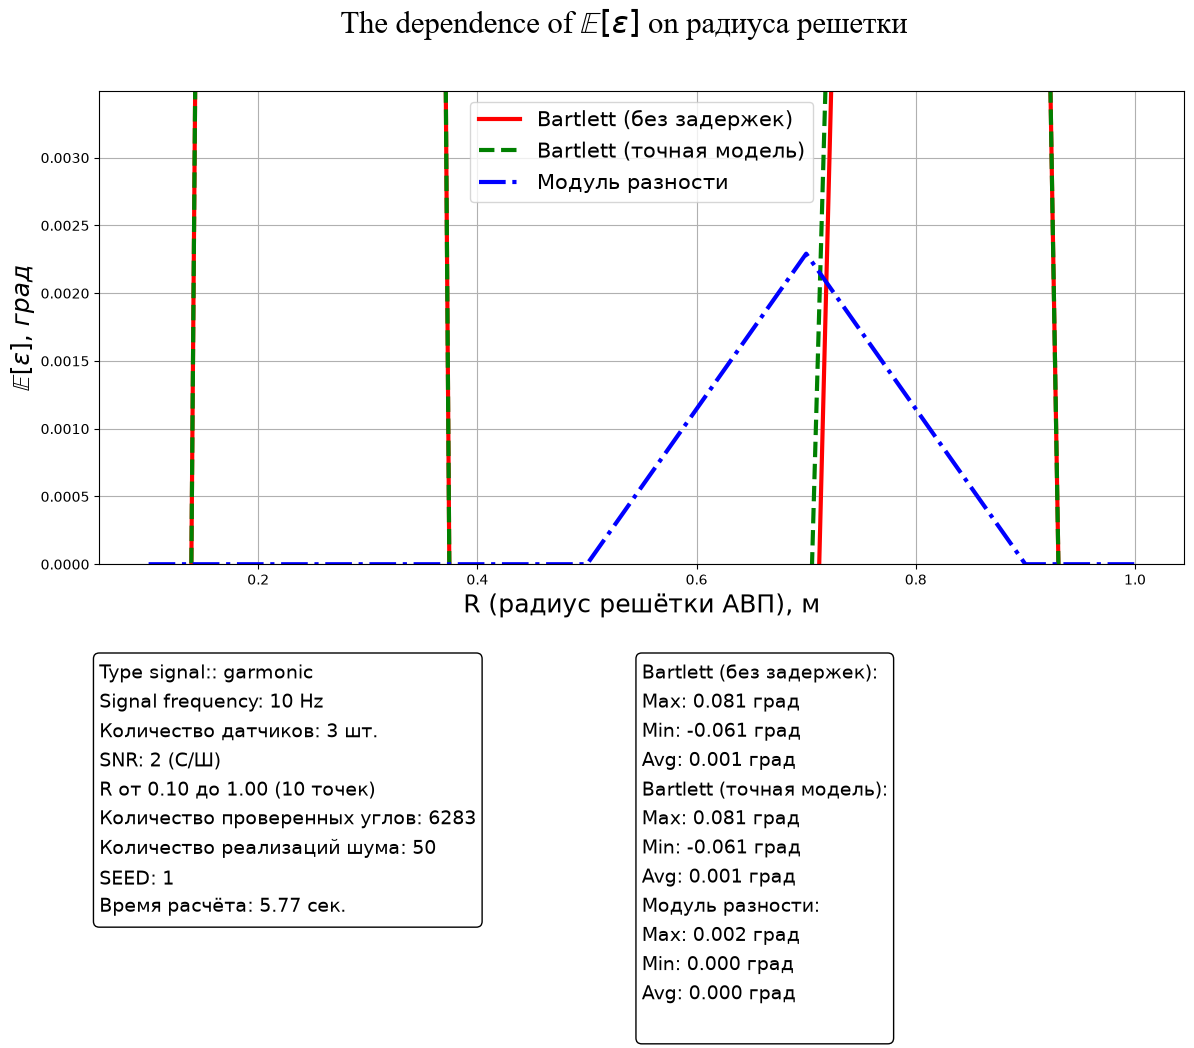

In [ ]:
plot_variance_vs_param(dict_values = {"Bartlett (без задержек)": var_bartlettt_vs_r,
                                      "Bartlett (точная model)": var_bartlettt_vs_r_complex,
                                      "Модуль разности": var_delta_abs},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (0, 0.2*comon.CONST_RADIAN),
                       type_signal = "garmonic",
                       **parametr_config
                       )
plot_mean_vs_param(dict_values = {"Bartlett (без задержек)": mean_bartlettt_vs_r,
                                  "Bartlett (точная model)": mean_bartlettt_vs_r_complex,
                                  "Модуль разности": mean_delta_abs},
                                  config_params = origin_config.copy(),
                                  delta_time = delta_time,
                                  ylim = (0, 0.2*comon.CONST_RADIAN),
                                  type_signal = "garmonic",
                                  **parametr_config)

In [45]:
config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = restart_rng(origin_config)
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "M",
    parametr_values = cfg.SENSOR_VALUES,
) 
var_bartlettt_vs_m = stat_vs_params(config_params=config_parametrs1,
                                    stat_func = calculate_variance,
                                    **config_bartlett_aprox,
                                    **parametr_config)
var_bartlettt_vs_m_complex = stat_vs_params(config_params = config_parametrs2,
                                   stat_func = calculate_variance,
                                   **config_bartlett_exact,
                                   **parametr_config)
var_delta_abs = np.abs(np.array(var_bartlettt_vs_m) - np.array(var_bartlettt_vs_m_complex))
config_parametrs1 = restart_rng(origin_config)
config_parametrs2 = restart_rng(origin_config)
mean_bartlettt_vs_m = stat_vs_params(config_params=config_parametrs1,
                                    stat_func = np.mean,
                                    **config_bartlett_aprox,
                                    **parametr_config)
mean_bartlettt_vs_m_complex = stat_vs_params(config_params=config_parametrs1,
                                    stat_func = np.mean,
                                    **config_bartlett_exact,
                                    **parametr_config)
mean_delta_abs = np.abs(np.array(mean_bartlettt_vs_m) - np.array(mean_bartlettt_vs_m_complex))
end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='M (кол-во датчиков), шт', ylabel='$\\mathbb{E}[\\varepsilon]$, $град$'>)

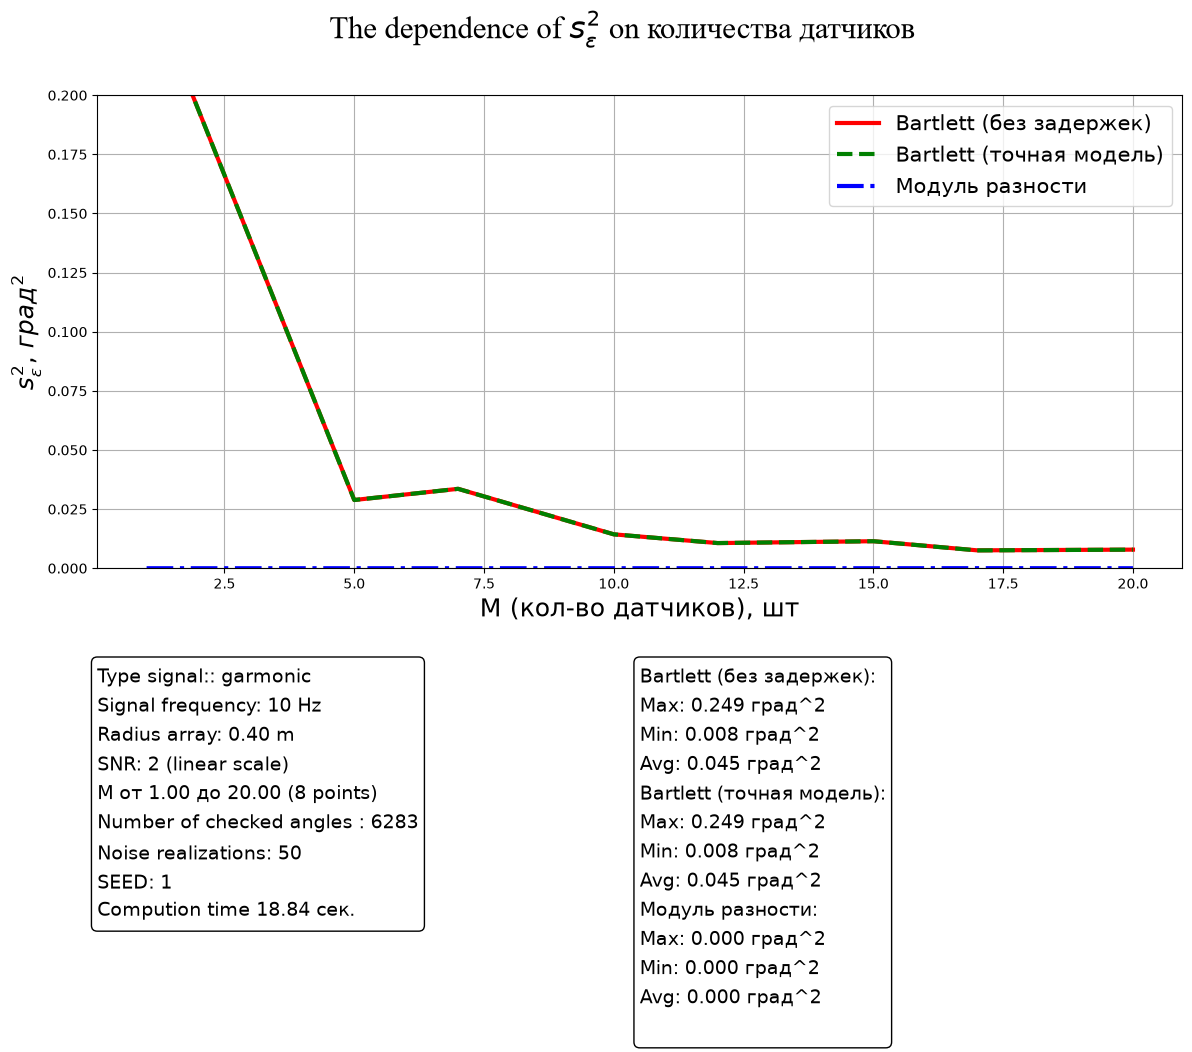

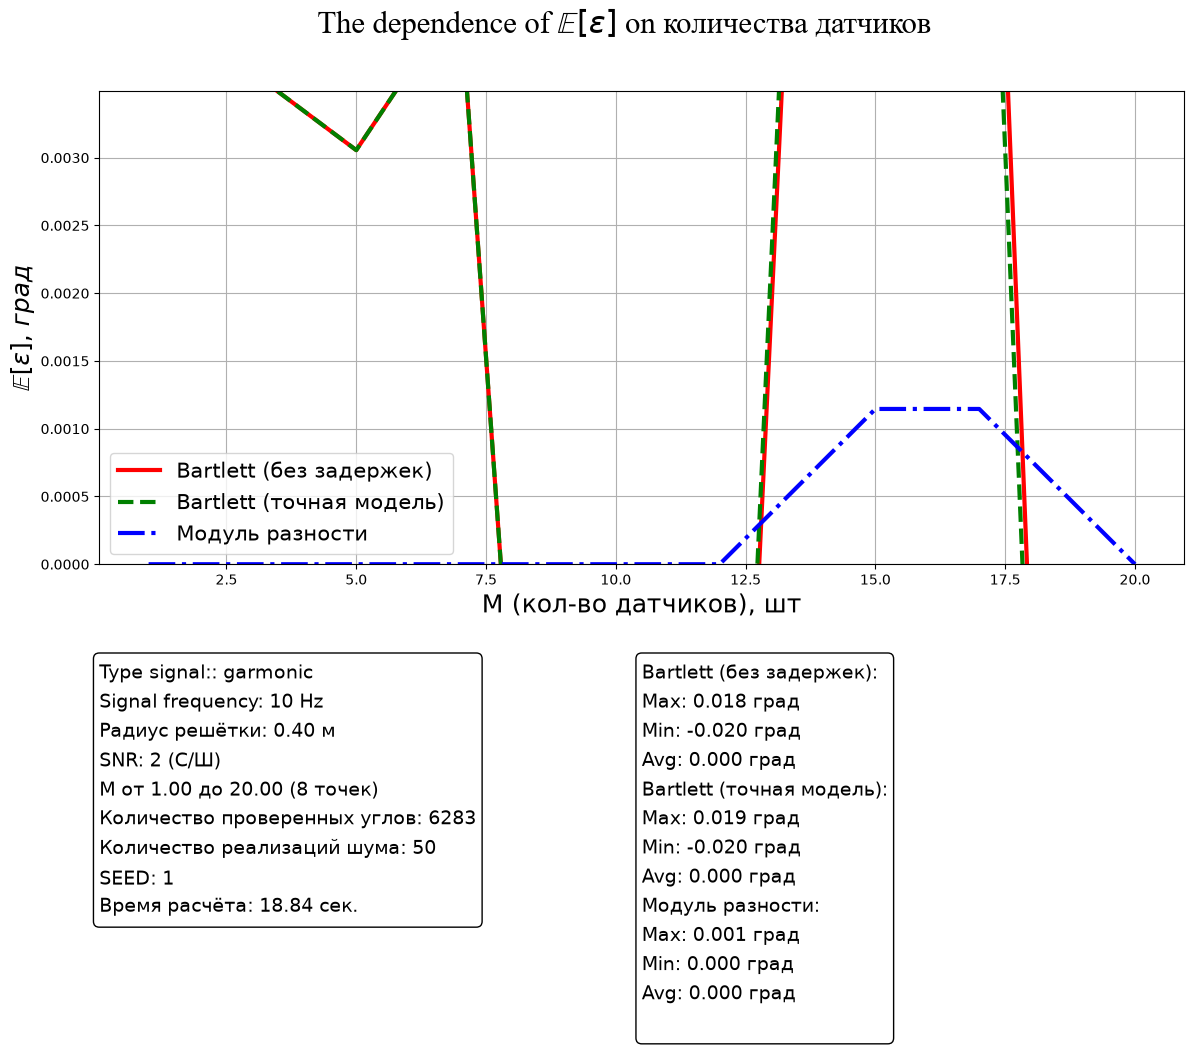

In [ ]:
plot_variance_vs_param(dict_values = {"Bartlett (без задержек)": var_bartlettt_vs_m,
                                      "Bartlett (точная model)": var_bartlettt_vs_m_complex,
                                      "Модуль разности": var_delta_abs},
                       config_params = origin_config.copy(),
                       delta_time = delta_time,
                       ylim = (0, 0.2*comon.CONST_RADIAN),
                       type_signal = "garmonic",
                       **parametr_config )
plot_mean_vs_param(dict_values = {"Bartlett (без задержек)": mean_bartlettt_vs_m,
                                  "Bartlett (точная model)": mean_bartlettt_vs_m_complex,
                                  "Модуль разности": mean_delta_abs},
                                  config_params = origin_config.copy(),
                                  delta_time = delta_time,
                                  ylim = (0, 0.2*comon.CONST_RADIAN),
                                  type_signal = "garmonic",
                                  **parametr_config)